#LABSHEET 7

##Step 1: Import the required Python libraries and load a video sequence or access a live webcam stream using OpenCV.




Saving 17408065-hd_1920_1080_30fps.mp4 to 17408065-hd_1920_1080_30fps.mp4
Video loaded successfully.


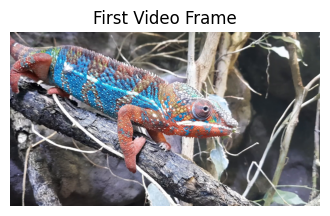

Name:  Aman Malik
CU24250099


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

cap = cv2.VideoCapture(filename)

print("Video loaded successfully.")

ret, frame = cap.read()

if ret:
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(4, 3))
    plt.imshow(frame)
    plt.title("First Video Frame")
    plt.axis("off")
    plt.show()

cap.release()

print("Name:  Aman Malik")
print("CU24250099")

##Step 2: Read consecutive video frames and convert them to grayscale for optical flow computation.


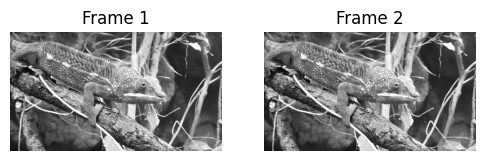

Frames converted to grayscale.
Name:  Aman Malik
CU24250099


In [2]:
cap = cv2.VideoCapture(filename)

ret1, frame1 = cap.read()
ret2, frame2 = cap.read()

gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(gray1, cmap="gray")
plt.title("Frame 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray2, cmap="gray")
plt.title("Frame 2")
plt.axis("off")

plt.show()
plt.close()

cap.release()

print("Frames converted to grayscale.")

print("Name:  Aman Malik")
print("CU24250099")

##Step 3 Implement the Lucas-Kanade Optical Flow algorithm to estimate the motion of selected feature points across consecutive frames.



In [3]:
from google.colab import files
import cv2
import numpy as np

uploaded = files.upload()
filename = next(iter(uploaded))

cap = cv2.VideoCapture(filename)

ret1, old_frame = cap.read()
ret2, new_frame = cap.read()
cap.release()

if ret1 and ret2:
    old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)
    new_gray = cv2.cvtColor(new_frame, cv2.COLOR_BGR2GRAY)

    points = cv2.goodFeaturesToTrack(
        old_gray, maxCorners=30,
        qualityLevel=0.3, minDistance=7
    )

    new_points, status, error = cv2.calcOpticalFlowPyrLK(
        old_gray, new_gray, points, None
    )

    print("Lucas-Kanade Optical Flow calculated.")
    print("Tracked points:", len(new_points))

else:
    print("Error: Could not read video frames.")

print("Name:  Aman Malik")
print("CU24250099")

Saving 17408065-hd_1920_1080_30fps.mp4 to 17408065-hd_1920_1080_30fps (1).mp4
Lucas-Kanade Optical Flow calculated.
Tracked points: 30
Name:  Aman Malik
CU24250099


##Step 4 Visualize the motion vectors by drawing arrows or trajectories representing the movement of tracked points.


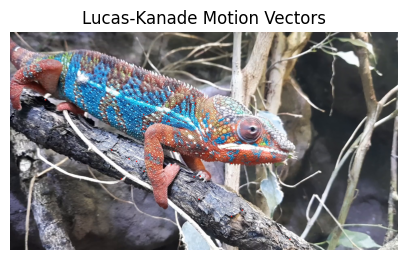

Name:  Aman Malik
CU24250099


In [4]:
cap = cv2.VideoCapture(filename)

ret1, old_frame = cap.read()
ret2, new_frame = cap.read()

cap.release()

if ret1 and ret2:
    old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)
    new_gray = cv2.cvtColor(new_frame, cv2.COLOR_BGR2GRAY)

    points = cv2.goodFeaturesToTrack(
        old_gray, maxCorners=30,
        qualityLevel=0.3, minDistance=7
    )

    new_points, status, _ = cv2.calcOpticalFlowPyrLK(
        old_gray, new_gray, points, None
    )

    output = new_frame.copy()

    for old, new, s in zip(points, new_points, status):
        if s == 1:
            x1, y1 = old.ravel().astype(int)
            x2, y2 = new.ravel().astype(int)

            cv2.arrowedLine(
                output, (x1, y1), (x2, y2),
                (0, 255, 0), 2
            )
            cv2.circle(output, (x2, y2), 3, (0, 0, 255), -1)

    plt.figure(figsize=(5, 3))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title("Lucas-Kanade Motion Vectors")
    plt.axis("off")
    plt.show()
    plt.close()

else:
    print("Error: Could not read two video frames.")

print("Name:  Aman Malik")
print("CU24250099")

##Step 5 Implement the Farneback Dense Optical Flow algorithm to estimate motion for every pixel in the image.


In [5]:
flow = cv2.calcOpticalFlowFarneback(
    gray1, gray2, None,
    0.5, 3, 15, 3, 5, 1.2, 0
)

print("Farneback Dense Optical Flow calculated.")
print("Flow shape:", flow.shape)

print("Name:  Aman Malik")
print("CU24250099")

Farneback Dense Optical Flow calculated.
Flow shape: (1080, 1920, 2)
Name:  Aman Malik
CU24250099


## Step 6 Display the dense optical flow output using color-coded motion visualization to represent direction and magnitude.



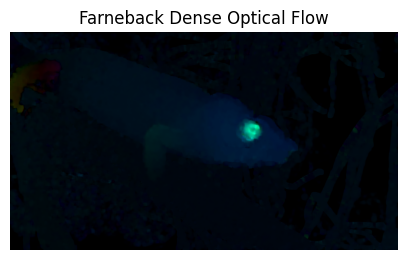

Color represents motion direction and brightness represents magnitude.
Name:  Aman Malik
CU24250099


In [6]:
mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])

hsv = np.zeros_like(cv2.cvtColor(frame1, cv2.COLOR_RGB2HSV))
hsv[..., 0] = ang * 180 / np.pi / 2
hsv[..., 1] = 255
hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)

flow_rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

plt.figure(figsize=(5, 3))
plt.imshow(flow_rgb)
plt.title("Farneback Dense Optical Flow")
plt.axis("off")
plt.show()
plt.close()

print("Color represents motion direction and brightness represents magnitude.")

print("Name:  Aman Malik")
print("CU24250099")

## Step 7 Compare the performance of Lucas-Kanade and Farneback algorithms in terms of accuracy, computational complexity, and robustness.


In [7]:
print("Optical Flow Comparison")
print("-----------------------")
print("Lucas-Kanade : Tracks selected feature points.")
print("Farneback    : Calculates motion for every pixel.")
print("Lucas-Kanade : Faster and computationally efficient.")
print("Farneback    : More detailed but computationally expensive.")
print("Lucas-Kanade : Suitable for sparse object tracking.")
print("Farneback    : Suitable for dense motion analysis.")

print("Name:  Aman Malik")
print("CU24250099")

Optical Flow Comparison
-----------------------
Lucas-Kanade : Tracks selected feature points.
Farneback    : Calculates motion for every pixel.
Lucas-Kanade : Faster and computationally efficient.
Farneback    : More detailed but computationally expensive.
Lucas-Kanade : Suitable for sparse object tracking.
Farneback    : Suitable for dense motion analysis.
Name:  Aman Malik
CU24250099


## Step 8 Analyze the effect of object speed, lighting conditions, and camera motion on optical flow estimation.


In [8]:
print("Effect on Optical Flow")
print("----------------------")
print("Object Speed : High speed can cause larger motion errors.")
print("Lighting     : Sudden lighting changes can affect tracking.")
print("Camera Motion: Camera movement creates motion across the image.")
print("Stable light and moderate motion give better results.")

print("Name:  Aman Malik")
print("CU24250099")

Effect on Optical Flow
----------------------
Object Speed : High speed can cause larger motion errors.
Lighting     : Sudden lighting changes can affect tracking.
Camera Motion: Camera movement creates motion across the image.
Stable light and moderate motion give better results.
Name:  Aman Malik
CU24250099


##Step 9 Evaluate the suitability of each algorithm for different real-world applications such as object tracking, surveillance, and autonomous navigation.


In [9]:
print("Algorithm Suitability")
print("---------------------")
print("Object Tracking       : Lucas-Kanade")
print("Surveillance          : Farneback")
print("Autonomous Navigation : Farneback")
print("Feature Tracking      : Lucas-Kanade")
print("Dense Motion Analysis : Farneback")

print("\nLucas-Kanade is preferred for fast tracking of selected points.")
print("Farneback is preferred when motion of the whole scene is required.")

print("Name:  Aman Malik")
print("CU24250099")

Algorithm Suitability
---------------------
Object Tracking       : Lucas-Kanade
Surveillance          : Farneback
Autonomous Navigation : Farneback
Feature Tracking      : Lucas-Kanade
Dense Motion Analysis : Farneback

Lucas-Kanade is preferred for fast tracking of selected points.
Farneback is preferred when motion of the whole scene is required.
Name:  Aman Malik
CU24250099


##Step 10 Summarize the observations and discuss the significance of optical flow in dynamic scene analysis and motion-based computer vision systems.


In [10]:
print("Observations:")
print("1. Lucas-Kanade tracks selected feature points.")
print("2. Farneback estimates dense motion over the image.")
print("3. Motion vectors show direction and movement.")
print("4. Lighting and camera motion affect optical flow.")
print("5. Optical flow is useful for tracking and scene analysis.")

print("\nConclusion:")
print("Optical flow is an important computer vision technique")
print("for analyzing motion in dynamic scenes and videos.")

print("Name:  Aman Malik")
print("CU24250099")

Observations:
1. Lucas-Kanade tracks selected feature points.
2. Farneback estimates dense motion over the image.
3. Motion vectors show direction and movement.
4. Lighting and camera motion affect optical flow.
5. Optical flow is useful for tracking and scene analysis.

Conclusion:
Optical flow is an important computer vision technique
for analyzing motion in dynamic scenes and videos.
Name:  Aman Malik
CU24250099
